In [1]:
import pandas as pd 
import numpy as np
import matplotlib as plt
import seaborn as sns

In [2]:
df= pd.read_csv(r'C:\Users\user\Smart_Waste_collection_Route_Optimization\Data\amravati_historical_waste.csv')
df.head()

,Bin_ID,Area_Type,Current_Fill_Pct,Actual_Fill_Rate,Hours_Left,Lat,Lon,days
0,B06,Market,33,12.38,5.41,20.95020,77.76579,Wednesday
1,B03,Transport,23,8.55,9.01,20.85750,77.73219,Monday
2,B04,Healthcare,37,3.58,17.60,20.93339,77.73219,Friday
3,B02,Commercial,62,9.18,4.14,20.92059,77.75428,Saturday
4,B02,Commercial,23,9.21,8.36,20.92059,77.75428,Tuesday


In [3]:
df.size

800

In [4]:
df.shape

(100, 8)

In [5]:
df.columns

Index(['Bin_ID', 'Area_Type', 'Current_Fill_Pct', 'Actual_Fill_Rate',
       'Hours_Left', 'Lat', 'Lon', 'days'],
      dtype='object')

In [6]:
df.info

<bound method DataFrame.info of    Bin_ID   Area_Type  Current_Fill_Pct  Actual_Fill_Rate  Hours_Left  \
0     B06      Market                33             12.38        5.41   
1     B03   Transport                23              8.55        9.01   
2     B04  Healthcare                37              3.58       17.60   
3     B02  Commercial                62              9.18        4.14   
4     B02  Commercial                23              9.21        8.36   
..    ...         ...               ...               ...         ...   
95    B06      Market                44             11.14        5.03   
96    B03   Transport                21              7.66       10.31   
97    B02  Commercial                66             10.75        3.16   
98    B02  Commercial                61             10.65        3.66   
99    B03   Transport                30              6.63       10.56   

         Lat       Lon       days  
0   20.95020  77.76579  Wednesday  
1   20.85750  77.73

In [7]:
df.describe()

,Current_Fill_Pct,Actual_Fill_Rate,Hours_Left,Lat,Lon
count,100.000000,100.000000,100.00000,100.000000,100.000000
mean,57.020000,7.606700,7.71290,20.911102,77.747117
std,22.314999,3.273113,8.07836,0.029603,0.011868
min,21.000000,0.710000,0.56000,20.857500,77.732190
25%,37.000000,5.242500,3.00750,20.895950,77.732190
50%,57.500000,7.110000,5.27500,20.920590,77.747540
75%,79.250000,10.655000,9.58000,20.933390,77.754280
max,94.000000,13.170000,48.19000,20.950200,77.765790


In [8]:
df.isnull().sum

<bound method DataFrame.sum of     Bin_ID  Area_Type  Current_Fill_Pct  Actual_Fill_Rate  Hours_Left    Lat  \
0    False      False             False             False       False  False   
1    False      False             False             False       False  False   
2    False      False             False             False       False  False   
3    False      False             False             False       False  False   
4    False      False             False             False       False  False   
..     ...        ...               ...               ...         ...    ...   
95   False      False             False             False       False  False   
96   False      False             False             False       False  False   
97   False      False             False             False       False  False   
98   False      False             False             False       False  False   
99   False      False             False             False       False  False   

      Lo

In [9]:
df['Current_Fill_Pct'].corr(df['Hours_Left'])


-0.45438122630240224

#In corelation between Current_Fill_Pct and Hours _Left is -0.409 which is negative value ,this also means that when current_fill_pct will incrase hourse left will decrease but also this correlation value is modrate there is also another feature who affects the hour left.

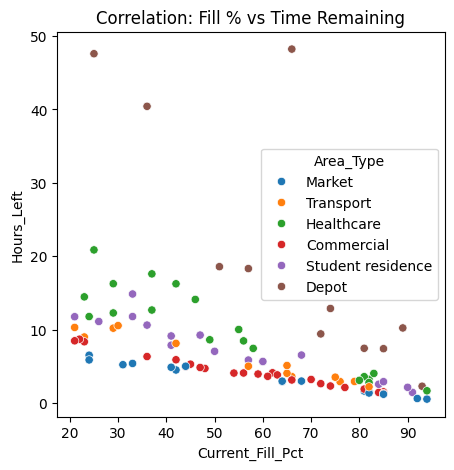

In [ ]:
#Scatter Plot: The Core Logic
import matplotlib.pyplot as plt
plt.figure(figsize=(5, 5))
sns.scatterplot(x='Current_Fill_Pct', y='Hours_Left', hue='Area_Type', data=df,palette="tab10")
plt.title("Correlation: Fill % vs Time Remaining")
plt.show()


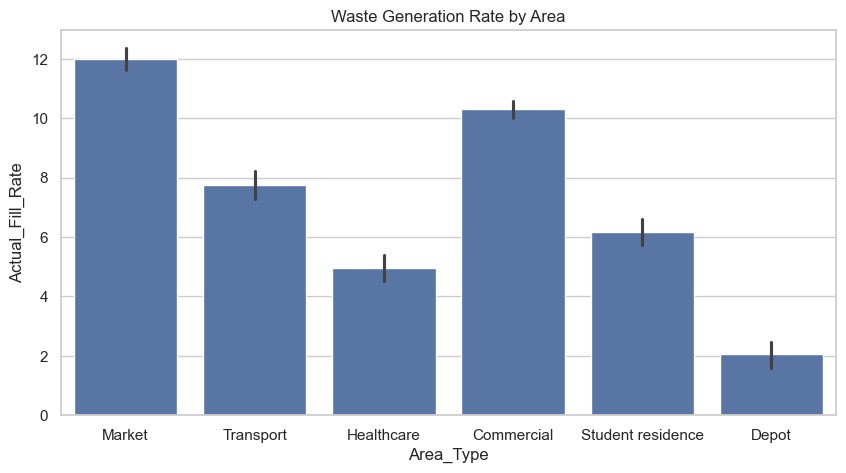

In [11]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.set_theme(style="whitegrid")
    
    # 1. Bar Chart: Which areas fill fastest?
plt.figure(figsize=(10, 5))
sns.barplot(x='Area_Type', y='Actual_Fill_Rate', data=df)
plt.title("Waste Generation Rate by Area")
plt.show()

    

Box Plot

In [15]:
plt.Figure(figsize=(10,5))
sns.boxplot(data=df,x='Current_fill_pct',y='days',palette=None)
plt.show()

ValueError: Could not interpret value `Current_fill_pct` for `x`. An entry with this name does not appear in `data`.

In [22]:
print(df.columns.tolist())

['Bin_ID', 'Area_Type', 'Current_Fill_Pct', 'Actual_Fill_Rate', 'Hours_Left', 'Lat', 'Lon', 'days']


In [23]:
# 1. Strip hidden spaces from column names
df.columns = df.columns.str.strip()

# 2. Convert column names to lowercase for easier typing
df.columns = df.columns.str.lower()

# 3. Now try to access it using lowercase
# We assume 'Current_fill_pct' becomes 'current_fill_pct'
print(df[['days', 'current_fill_pct']].dtypes)

days                object
current_fill_pct     int64
dtype: object


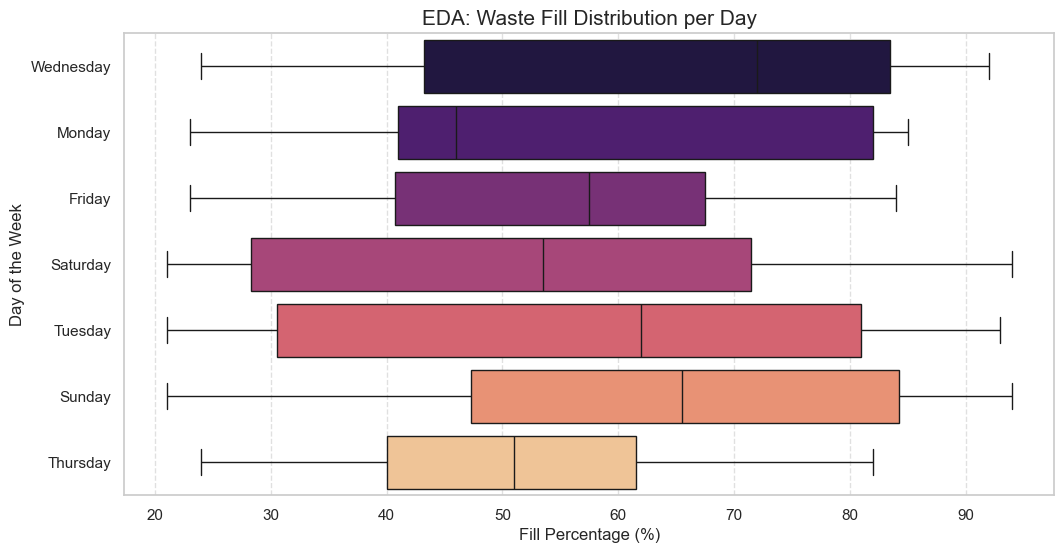

In [24]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='current_fill_pct', y='days', hue='days', palette='magma', legend=False)

plt.title('EDA: Waste Fill Distribution per Day', fontsize=15)
plt.xlabel('Fill Percentage (%)', fontsize=12)
plt.ylabel('Day of the Week', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.show()

In [25]:
plt.figure(figsize=(12, 6))
sns.boxplot(data=df, x='current_fill_pct', y='Area_Type', hue='Hours_left', palette='magma', legend=False)

plt.title('EDA: Waste Fill Distribution according to area ', fontsize=15)
plt.xlabel('Fill Percentage (%)', fontsize=12)
plt.ylabel('Area_Types', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

plt.show()

ValueError: Could not interpret value `Area_Type` for `y`. An entry with this name does not appear in `data`.

<Figure size 1200x600 with 0 Axes>

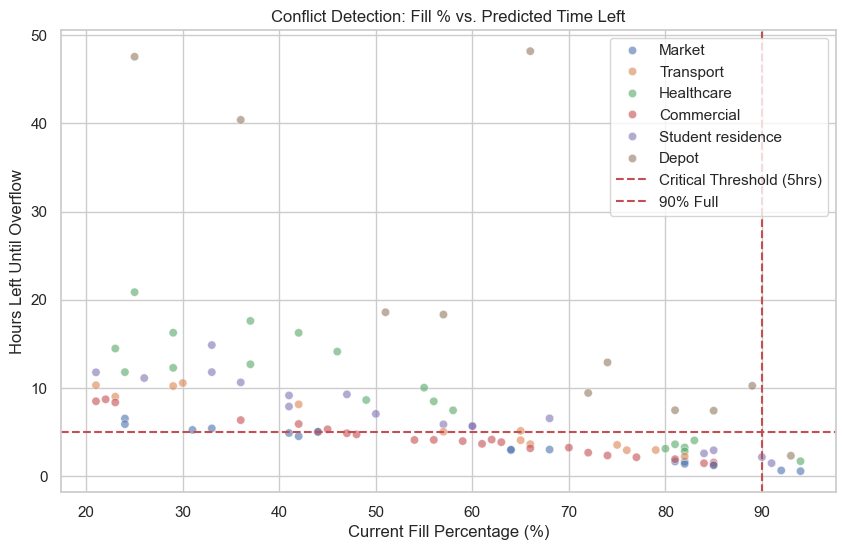

In [31]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='current_fill_pct', y='hours_left', alpha=0.6,hue='area_type')

# Adding a 'Warning' line: High fill should have low time
plt.axhline(y=5, color='r', linestyle='--', label='Critical Threshold (5hrs)')
plt.axvline(x=90, color='r', linestyle='--', label='90% Full')

plt.title('Conflict Detection: Fill % vs. Predicted Time Left')
plt.xlabel('Current Fill Percentage (%)')
plt.ylabel('Hours Left Until Overflow')
plt.legend()
plt.show()

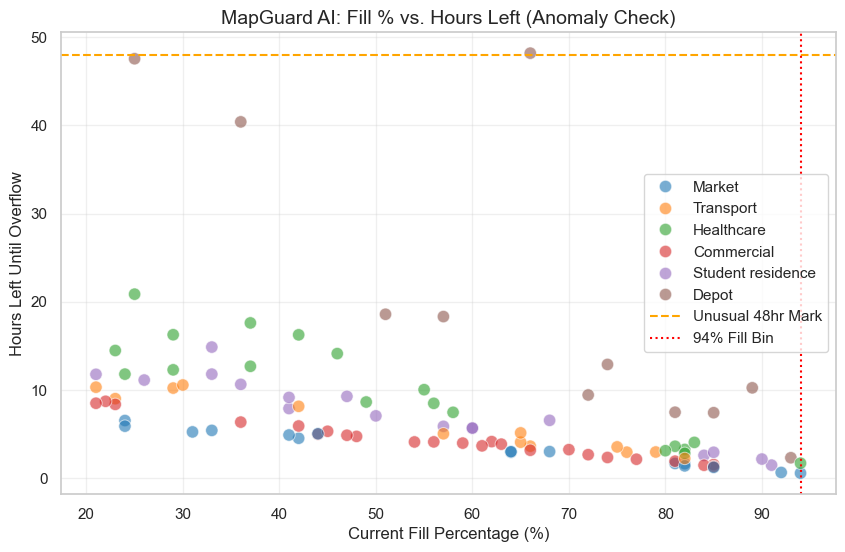

In [36]:
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure columns are standardized
df.columns = df.columns.str.strip().str.lower()

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x='current_fill_pct', y='hours_left', color='blue', alpha=0.6, s=80,hue='area_type',palette="tab10")

# Add a horizontal line at 48 hours to highlight your observation
plt.axhline(y=48, color='orange', linestyle='--', label='Unusual 48hr Mark')
# Add a vertical line at 94% to pinpoint the specific bin you found
plt.axvline(x=94, color='red', linestyle=':', label='94% Fill Bin')

plt.title('MapGuard AI: Fill % vs. Hours Left (Anomaly Check)', fontsize=14)
plt.xlabel('Current Fill Percentage (%)')
plt.ylabel('Hours Left Until Overflow')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [29]:
print("Available columns:", df.columns.tolist())

Available columns: ['bin_id', 'area_type', 'current_fill_pct', 'actual_fill_rate', 'hours_left', 'lat', 'lon', 'days']


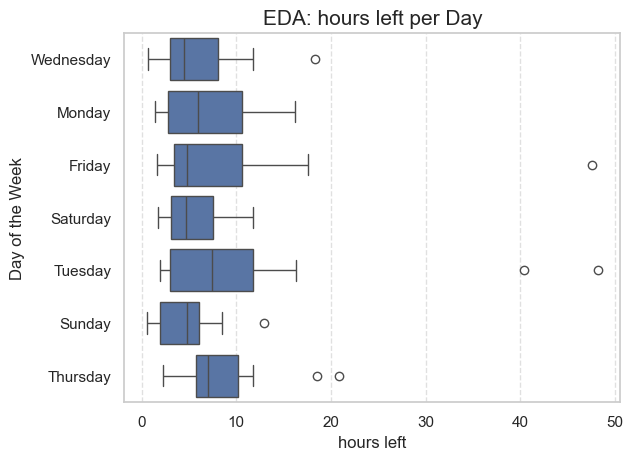

In [37]:
plt.Figure(figsize=(10,5))
sns.boxplot(data=df,x='hours_left',y='days')
plt.title('EDA: hours left per Day', fontsize=15)
plt.xlabel('hours left', fontsize=12)
plt.ylabel('Day of the Week', fontsize=12)
plt.grid(axis='x', linestyle='--', alpha=0.6)

